# T32 clean rerun: robust local comb solver

Companion to `README.md`. Each section re-runs one figure script (from `data/` or the named `runs/t32_clean/` outputs) and shows the figure. Heavy steps (Stage-1 caches, Stage-2 screen, scorecards, profiling) are scripts; see README "Reproduce".

In [1]:
import subprocess, sys, os
from pathlib import Path
from IPython.display import Image, display
HERE = Path.cwd()
PY = sys.executable
def run(*args):
    r = subprocess.run([PY, *args], cwd=HERE, capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:])


## 1. Free vertex residual vs n (step 1)
From `data/vertex_residuals.csv` (made by `diag_vertex.py`). Gains: early teeth on the line, late teeth walk out of the frozen seed windows. none→wrong: low acceptance and scatter from n = 1.

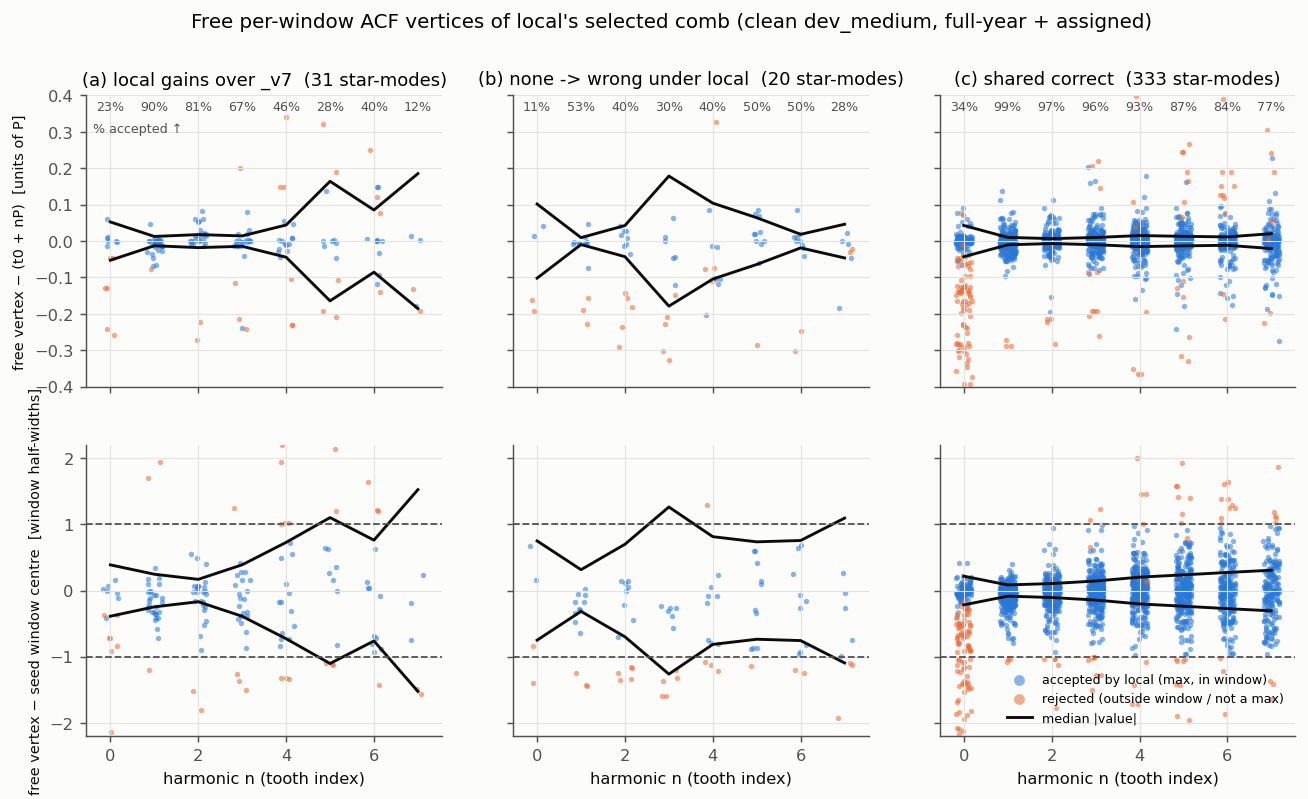

In [2]:
run('fig_vertex.py'); display(Image('figures/fig_vertex_residual_vs_n.png'))

## 2. Screen summary and outcomes by period bin
Stage-2 harness = scorecard per star (checked for local, local_screen2, local_seq, local_seq_trim, local_trim in both modes).

In [3]:
run('summarize.py')
import pandas as pd
pd.read_csv('data/screen_summary.csv')

4   0.1247 0.0046 0.0160 0.8547       1    20           1          12        0.0818      0.0924
       local_quad   as 874   0.1236 0.0034 0.0126 0.8604       2    22           1          14        0.0767      0.0827
   local_seq_snrw   as 874   0.1190 0.0080 0.0137 0.8593       5    29           1          14        0.0987      0.1110
       local_tol1   as 874   0.1098 0.0046 0.0103 0.8753       1    33           0          16        0.0729      0.0763
       local_snrw   as 874   0.1053 0.0046 0.0092 0.8810       1    37           0          17        0.0685      0.0724
       local_trim   fy 874   0.2712 0.0103 0.0378 0.6808      25    10           9           8        0.1214      0.1228
            local   fy 874   0.2643 0.0092 0.0378 0.6888      21    12           9           9        0.1071      0.1150
    local_screen2   fy 874   0.2540 0.0080 0.0378 0.7002       0     0           0           0        0.5673      0.6142
              _v7   fy 874   0.2540 0.0080 0.0378 0.7002 

,variant,mode,n,success,alias,wrong,none,gained,lost,none2wrong,wrong2none,fit_s_median,fit_s_mean
0,local_free,fy,874,0.2243,0.0069,0.0240,0.7449,8,34,1,11,0.1112,0.1140
1,local,fy,874,0.2643,0.0092,0.0378,0.6888,21,12,9,9,0.1071,0.1150
2,local_quad,fy,874,0.2105,0.0046,0.0103,0.7746,7,45,0,21,0.1200,0.1252
3,local_scatter,fy,874,0.2483,0.0103,0.0195,0.7220,16,21,3,17,0.1207,0.1284
4,local_screen2,fy,874,0.2540,0.0080,0.0378,0.7002,0,0,0,0,0.5673,0.6142
5,local_seq_free,fy,874,0.2300,0.0092,0.0114,0.7494,16,37,2,23,0.1333,0.1362
6,local_seq,fy,874,0.2494,0.0103,0.0206,0.7197,22,26,7,20,0.1355,0.1438
7,local_seq_quad,fy,874,0.2254,0.0092,0.0092,0.7563,15,40,2,25,0.1329,0.1339
8,local_seq_scatter,fy,874,0.2346,0.0080,0.0114,0.7460,23,40,3,25,0.1356,0.1393
9,local_seq_snrw,fy,874,0.1968,0.0114,0.0069,0.7849,14,64,2,27,0.1352,0.1358


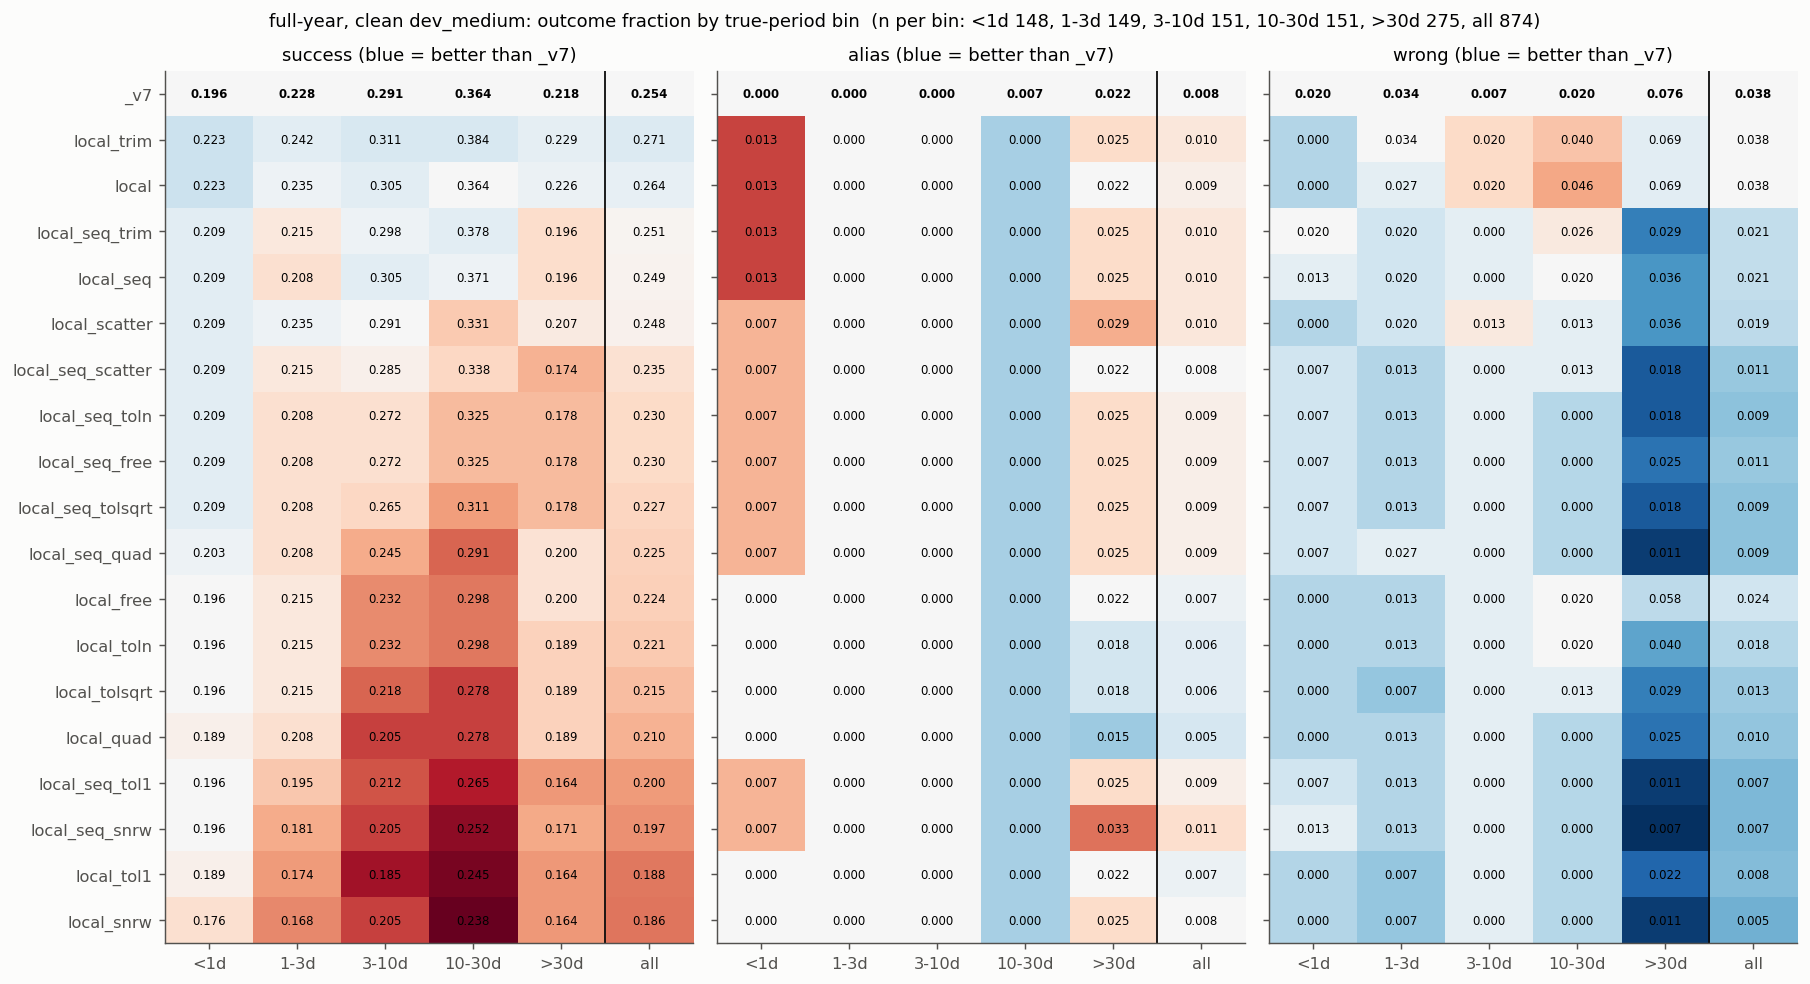

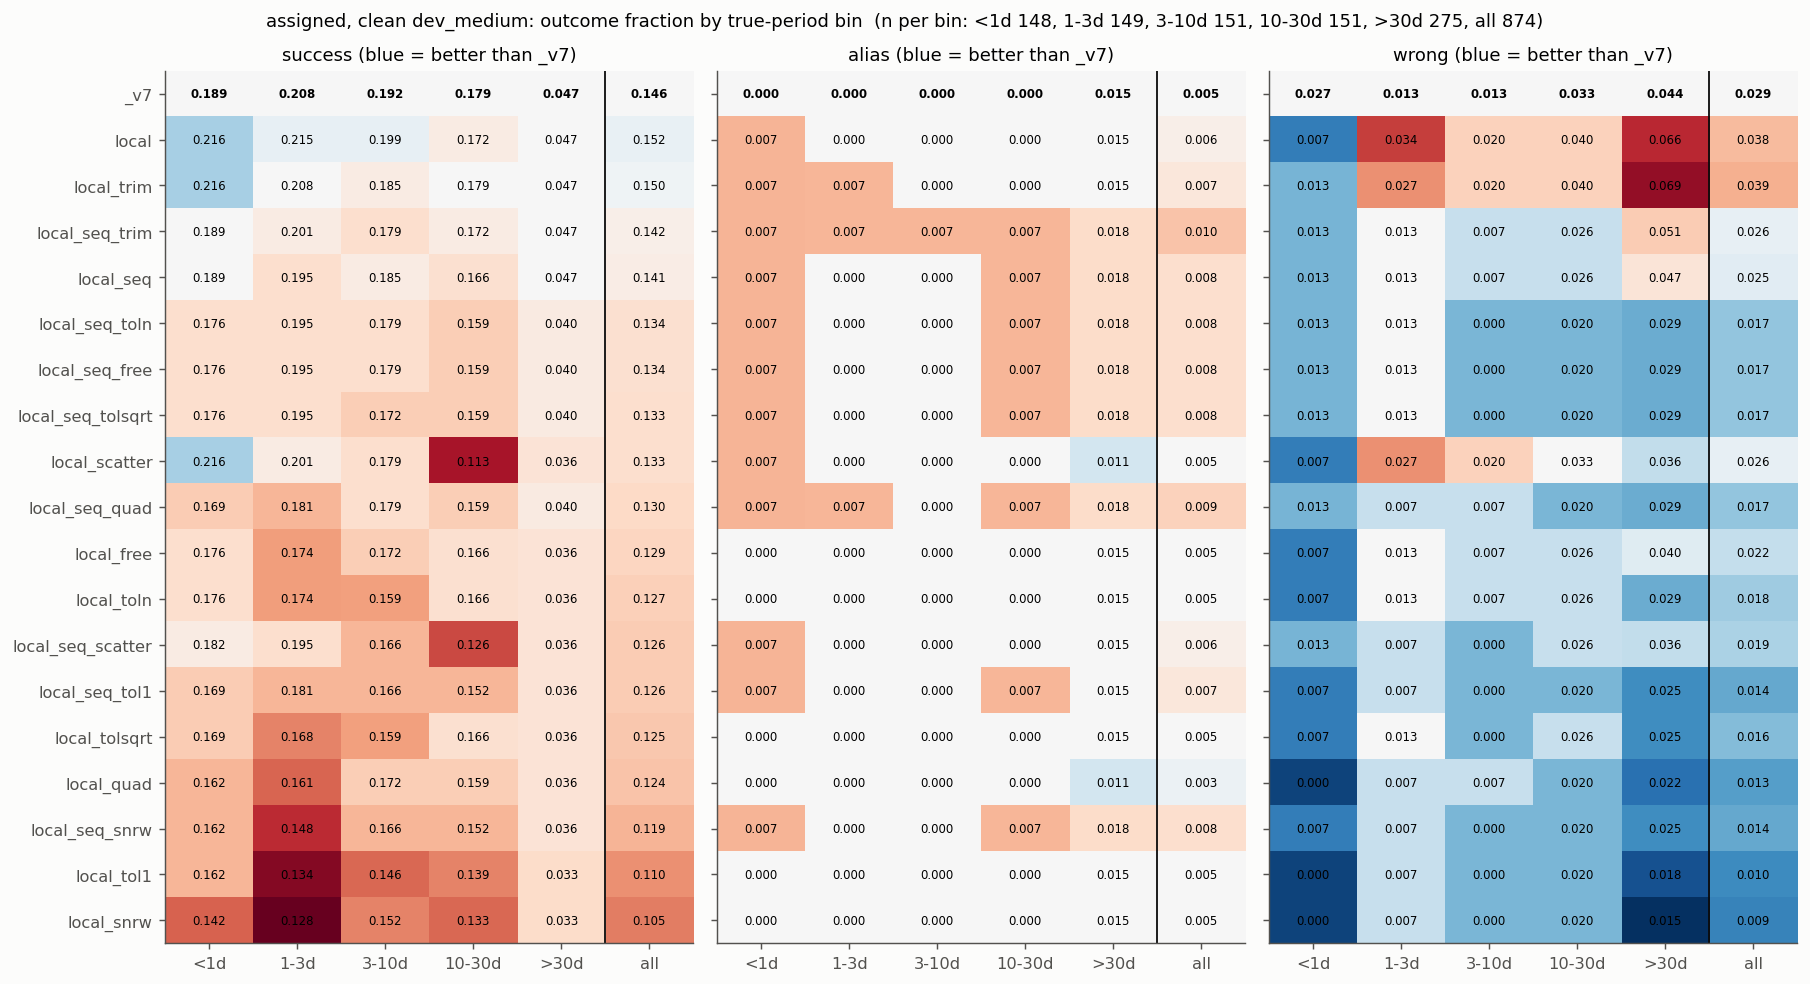

In [4]:
run('fig_bins.py'); display(Image('figures/fig_by_bin_fy.png')); display(Image('figures/fig_by_bin_as.png'))

## 3. Leader's lost stars: which gate fails

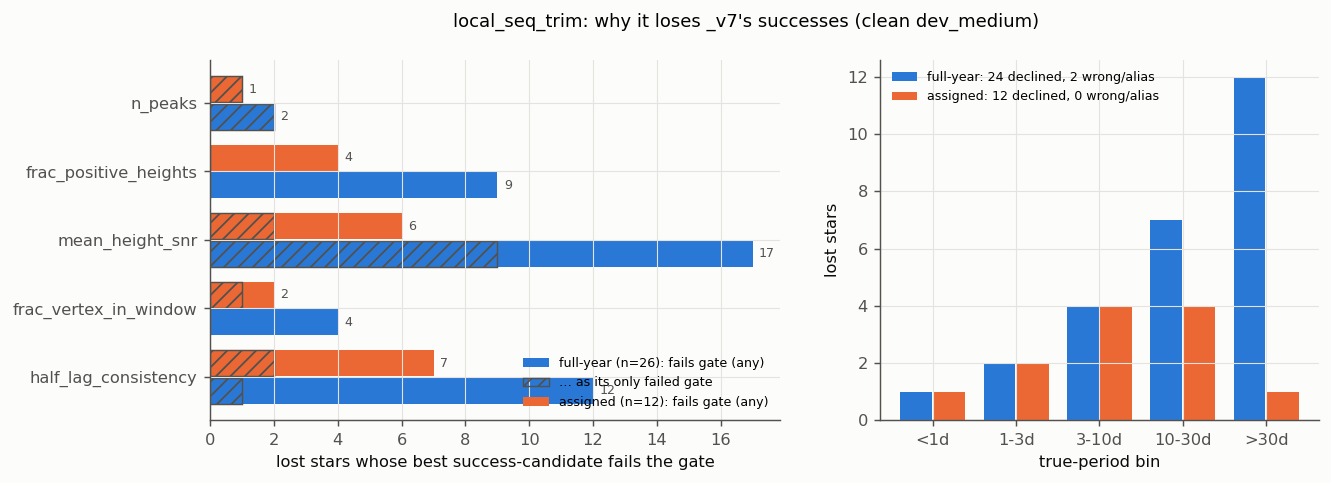

In [5]:
run('fig_gates.py', 'local_seq_trim'); display(Image('figures/fig_leader_lost_gates.png'))

## 4. Speed vs success, runtime bars

       variant    fit  features  production  scorecard  total_with_features  other
           lsq 1.0347    0.1417      1.1322     1.5751               1.7169 0.5404
 local_screen2 0.5153    0.1515      0.6082     1.0706               1.2221 0.5553
         local 0.1033    0.1367      0.1978     0.6200               0.7567 0.5167
    local_trim 0.1141    0.1442      0.2126     0.6574               0.8016 0.5433
     local_seq 0.1312    0.1417      0.2198     0.6489               0.7905 0.5176
local_seq_trim 0.1297    0.1409      0.2165     0.6439               0.7848 0.5143
 


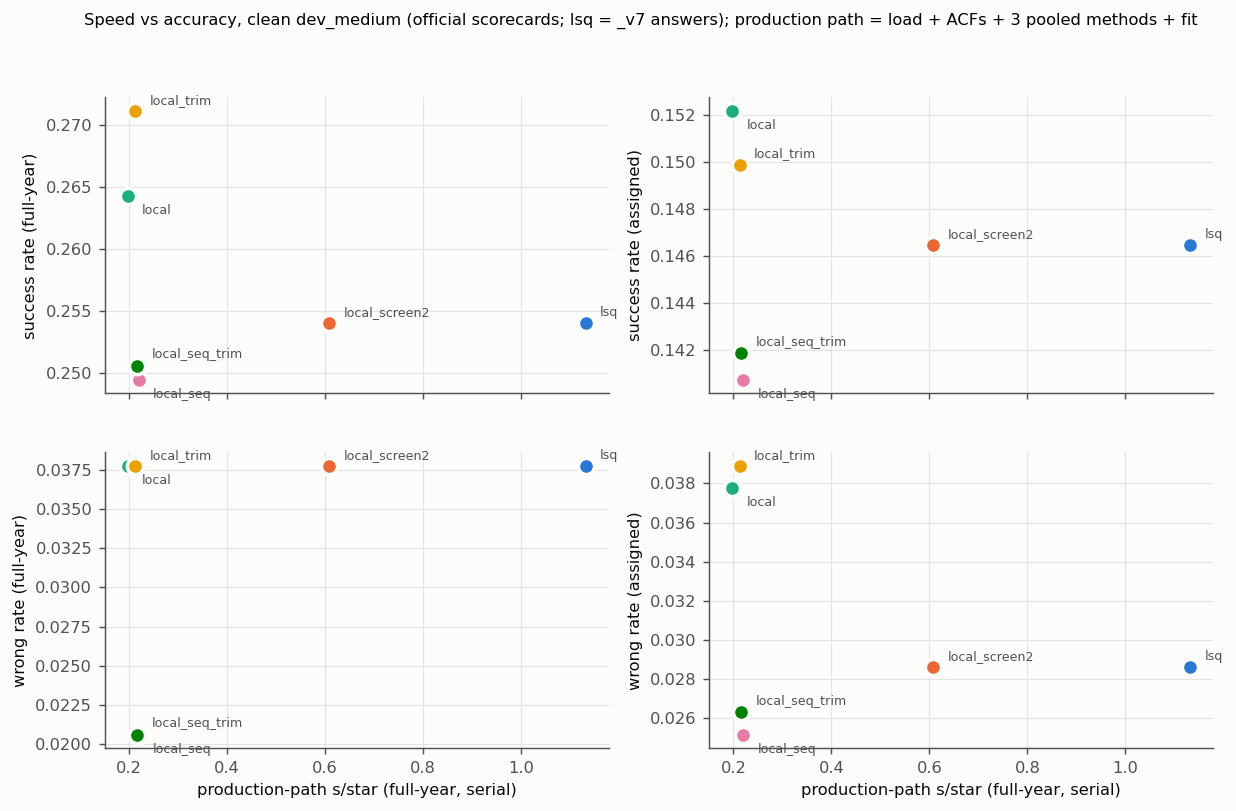

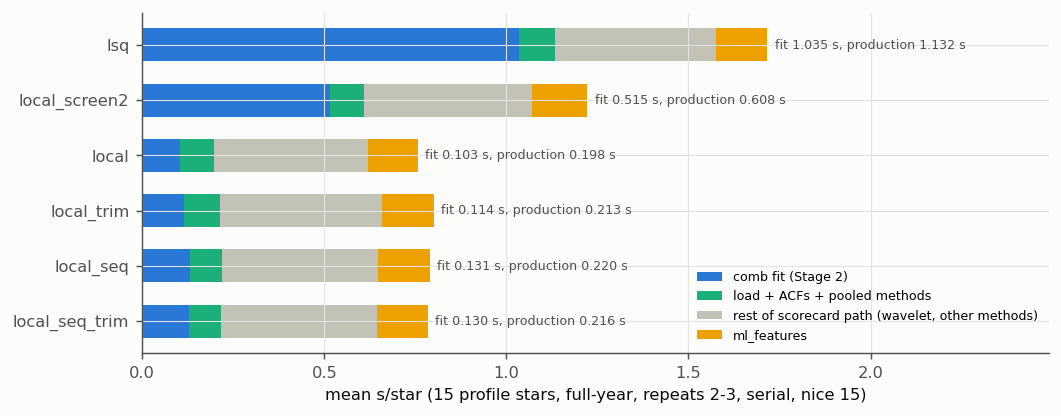

In [6]:
run('fig_speed.py'); display(Image('figures/fig_speed_vs_success.png')); display(Image('figures/fig_runtime_bars.png'))

## 5. Example stars (LC + ACF with windows, fitted teeth and vertices)
Needs the Stage-1 caches in `runs/t32_clean/cache_{fy,as}`.

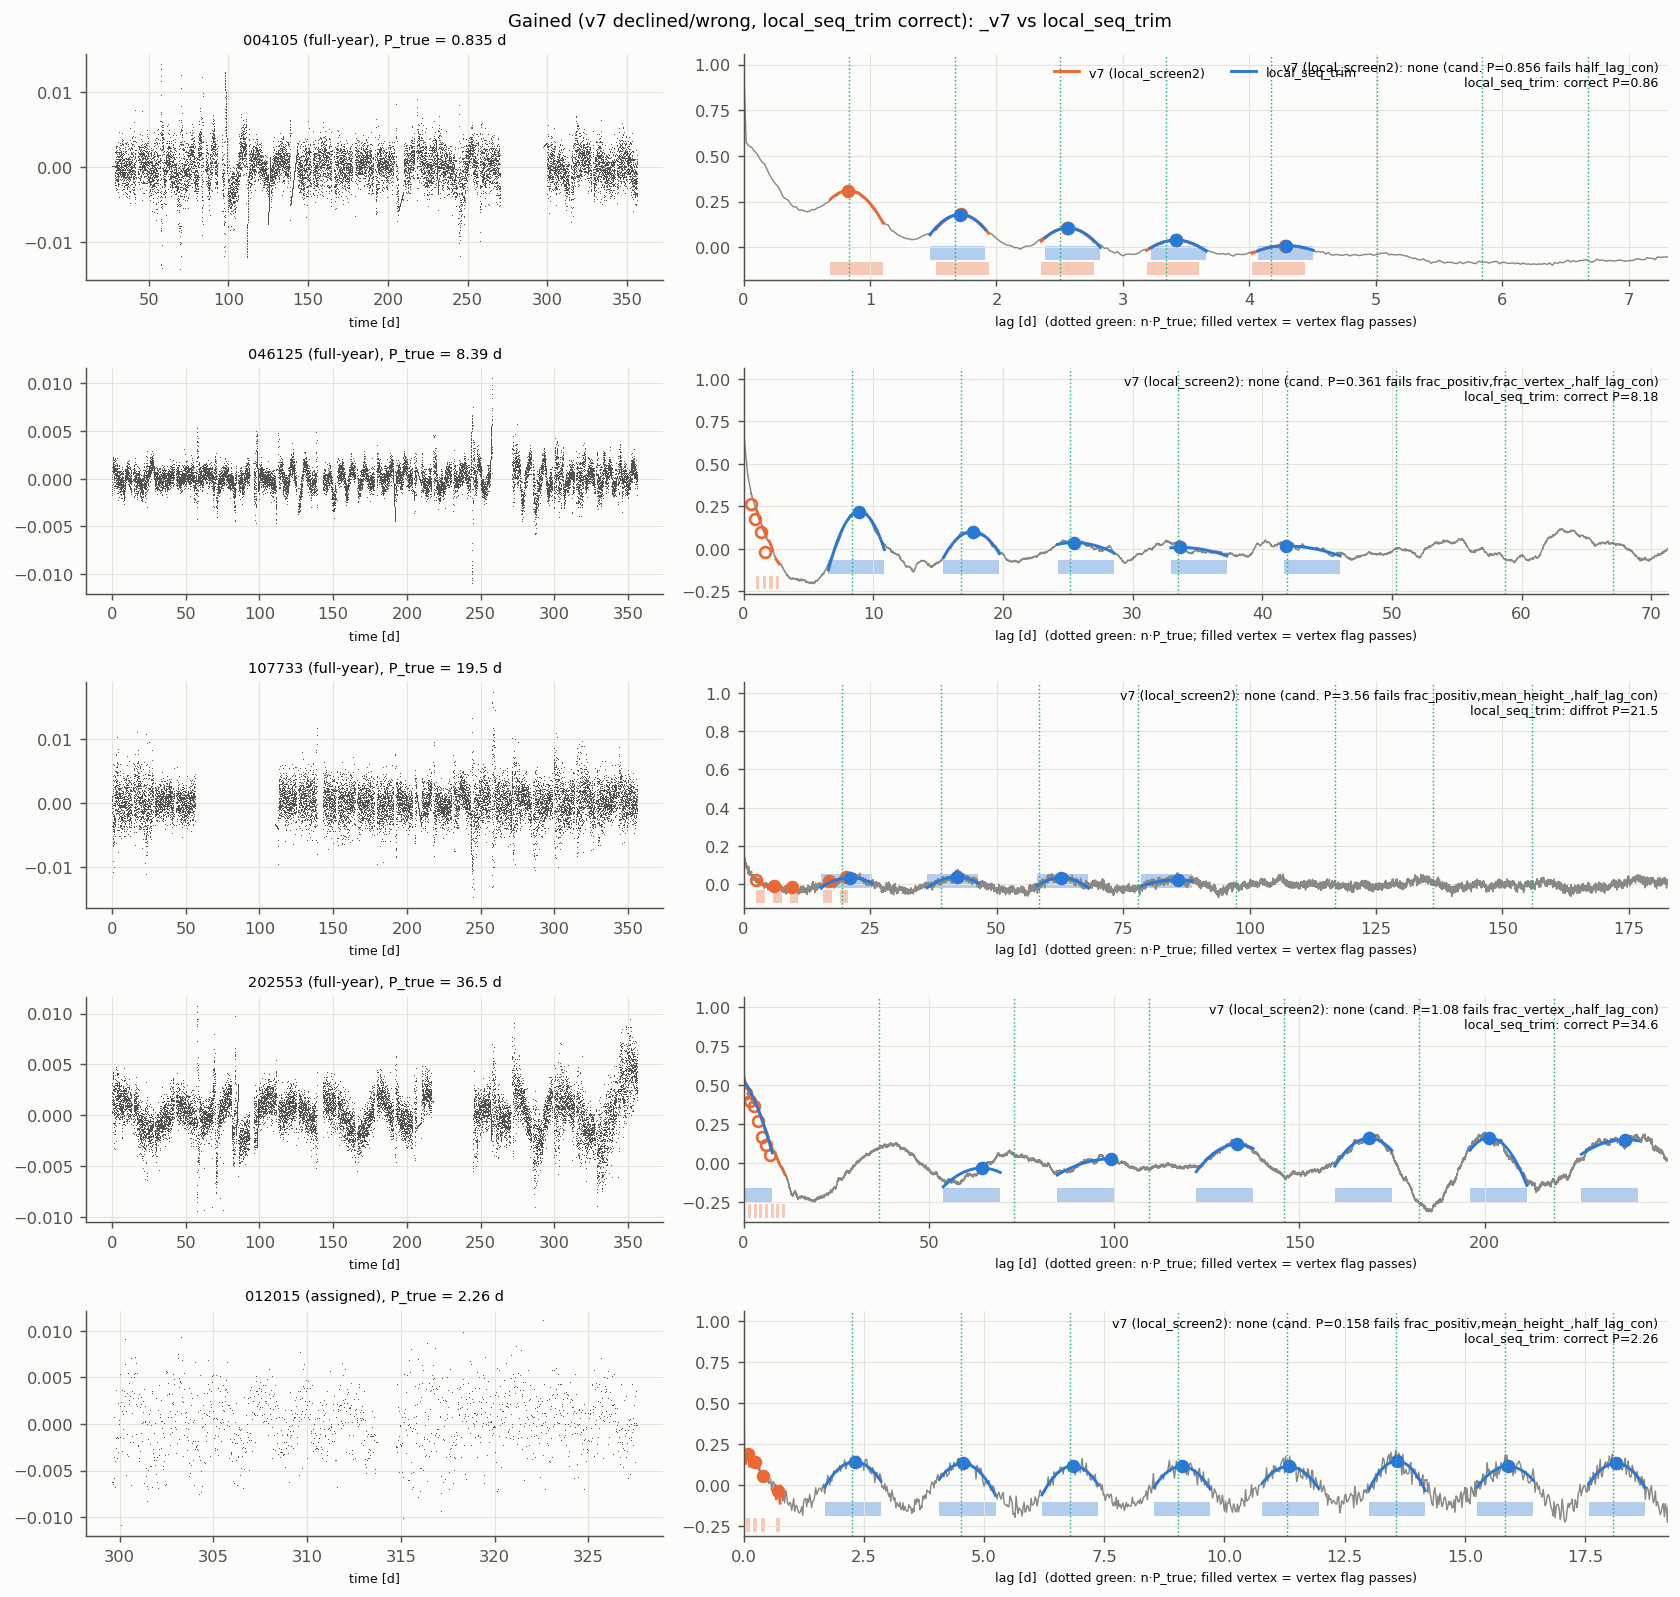

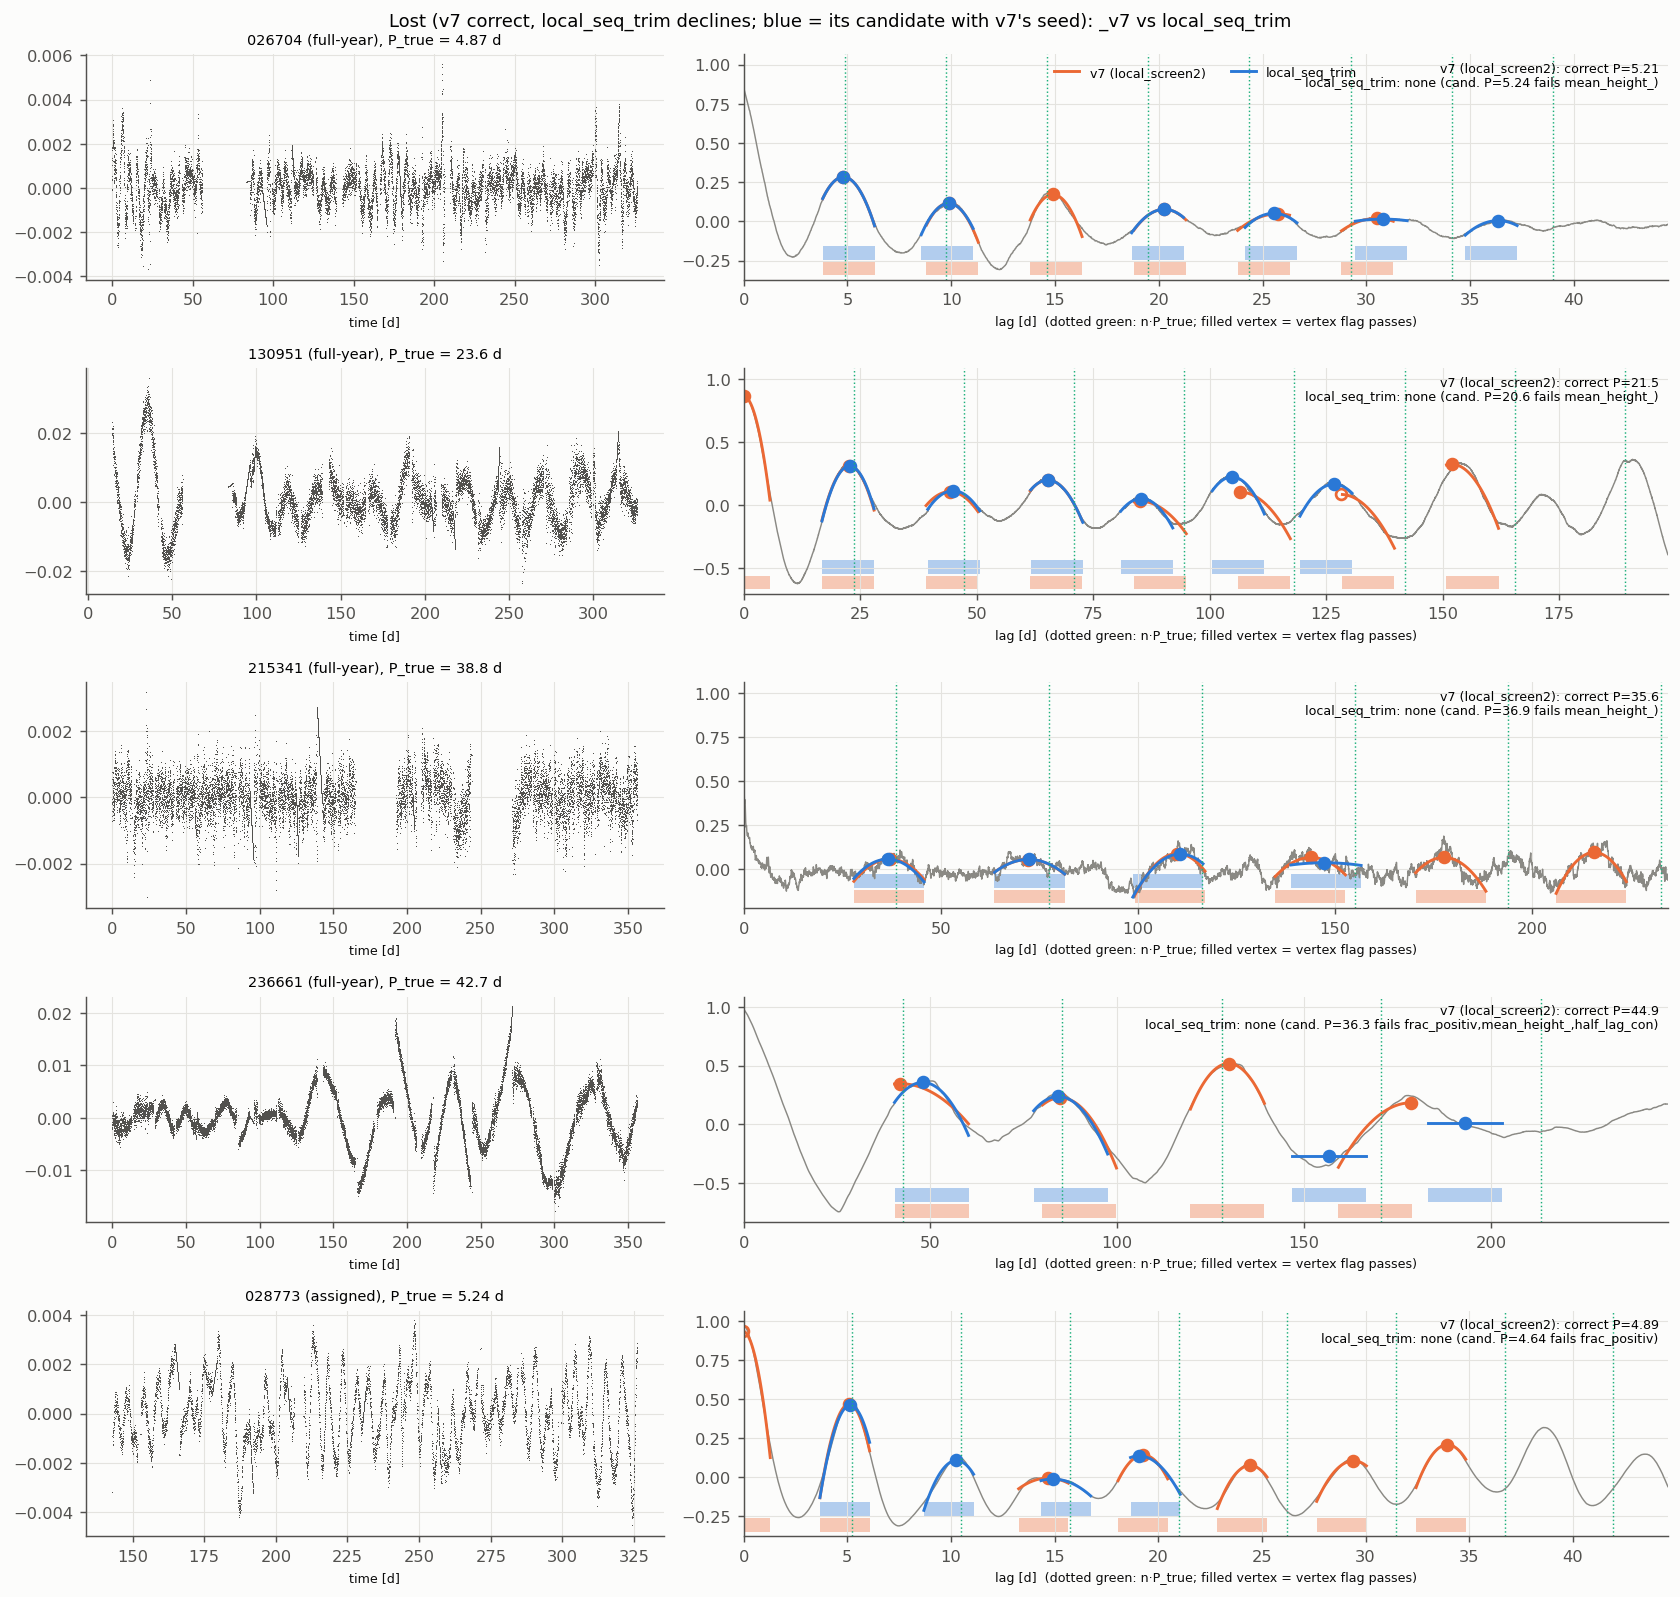

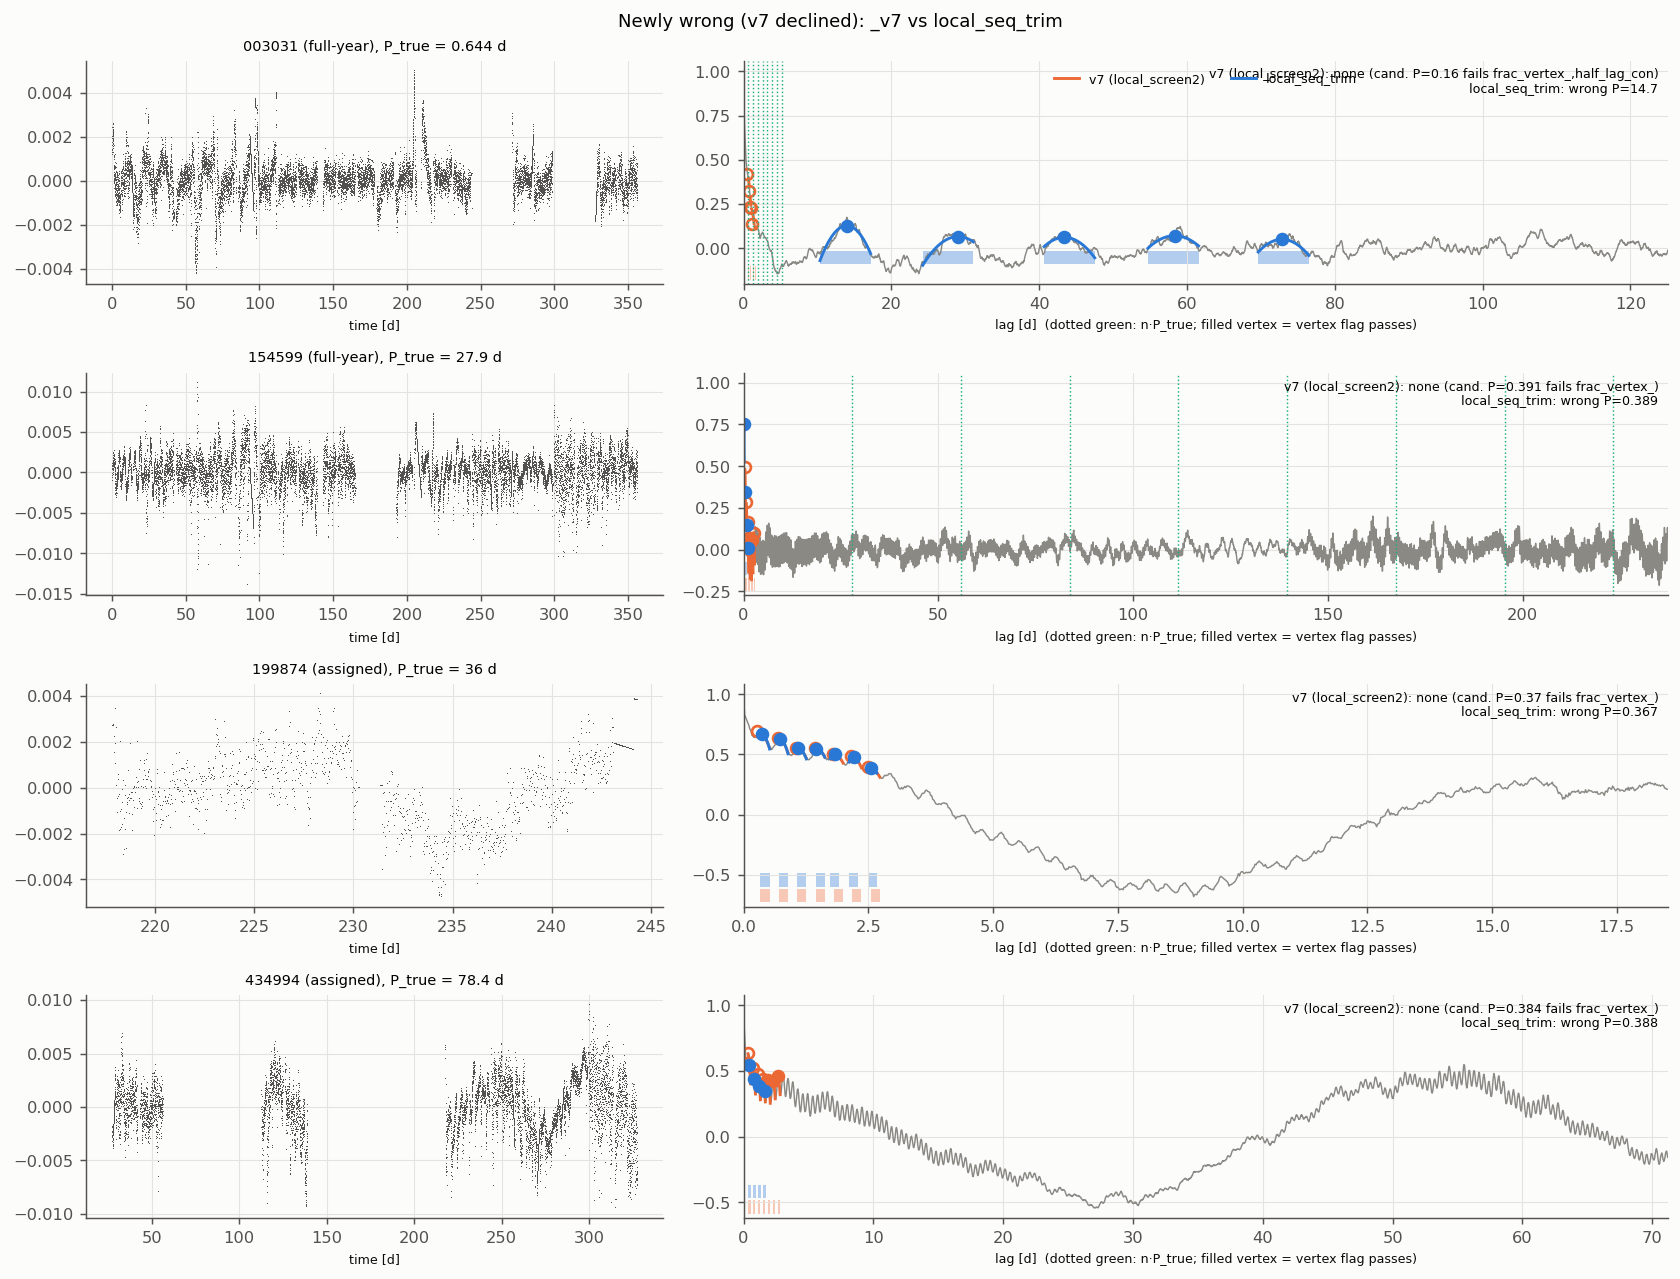

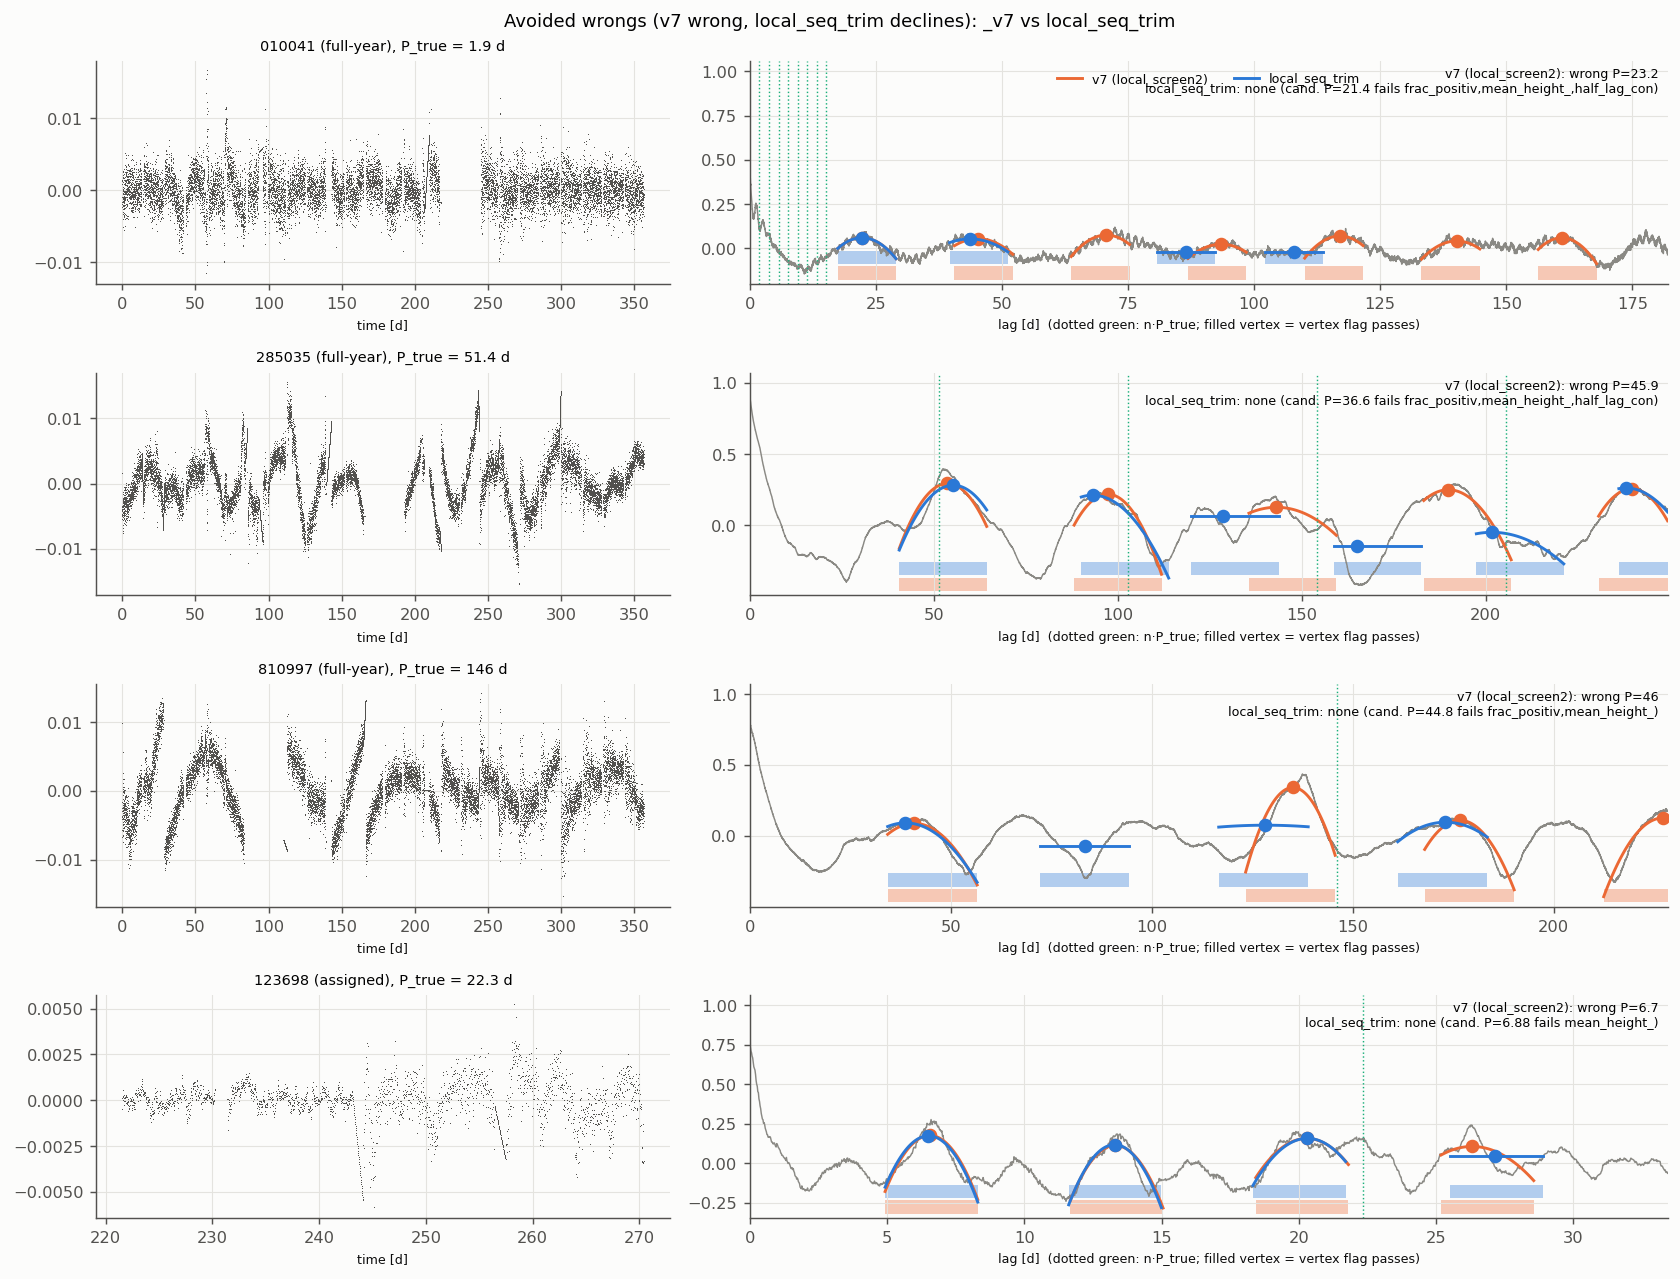

In [7]:
P = 'smarts-tess-v1.0-'
sets = {
 'fig_examples_gained.png': ('Gained (v7 declined/wrong, local_seq_trim correct)', ['004105:fy','046125:fy','107733:fy','202553:fy','012015:as']),
 'fig_examples_lost.png': ("Lost (v7 correct, local_seq_trim declines; blue = its candidate with v7's seed)", ['026704:fy','130951:fy','215341:fy','236661:fy','028773:as']),
 'fig_examples_newly_wrong.png': ('Newly wrong (v7 declined)', ['003031:fy','154599:fy','199874:as','434994:as']),
 'fig_examples_avoided_wrong.png': ('Avoided wrongs (v7 wrong, local_seq_trim declines)', ['010041:fy','285035:fy','810997:fy','123698:as'])}
for out, (title, stars) in sets.items():
    run('fig_examples.py', 'local_seq_trim', title, out, *[P + s for s in stars])
    display(Image('figures/' + out))